# Both faces of the detector, and which channels the Side-2 readout reads

*Draft figure for an appendix of Note 9.* The detector has two faces, each with the same six phonon sensors (A the outer ring, B the second ring, C, D and E the three sectors of the middle region, F the centre disc). In **Side-2 readout**, the readout of series `07221203_2025`, only the six sensors of **Side 2** are connected to a DCRC; the six of Side 1 exist on the detector but are not read out. The figure draws both faces, with the Side-2 sensors coloured by the readout board and each region labelled with its board input, and the Side-1 sensors greyed out, with the board input they would use in Side-1 readout.

The map comes from `python/pulse_channels.py` (`sensor_channels(readout=2)` for Side 2 and `sensor_channels(readout=1)` for Side 1), which reads the *Setup* table of the Run 76 summary. No data is needed: the notebook only draws. The geometry is the wiki's (face 2 is drawn as seen after flipping the detector over; only the x axis points the other way).

Run with the `darkmatter_cli_env` kernel. *Author: draft prepared with Claude Code for A. Villano, 2026-10-23.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Patch

import pulse_channels as pch

warnings.filterwarnings("ignore", message=".*under_development.*")     # the mapping is tagged under development
DUMP = "07221203_2025_F0001"
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

side2 = {c.letter: c for c in pch.sensor_channels(readout=2)}      # what this series reads
side1 = {c.letter: c for c in pch.sensor_channels(readout=1)}      # what the Side-1 readout would read
for letter in "ABCDEF":
    print(f"{letter}:  Side 2 -> {side2[letter].name} on {side2[letter].dcrc} {side2[letter].board_input} ({side2[letter].hv_output});"
          f"   Side 1 -> {side1[letter].name} on {side1[letter].dcrc} {side1[letter].board_input} ({side1[letter].hv_output})")

A:  Side 2 -> Side2pA on DCRC3 pB (HV1 pB);   Side 1 -> Side1pA on DCRC1 pB (HV2 pB)
B:  Side 2 -> Side2pB on DCRC3 pA (HV1 pA);   Side 1 -> Side1pB on DCRC3 pB (HV1 pB)
C:  Side 2 -> Side2pC on DCRC1 pA (HV2 pA);   Side 1 -> Side1pC on DCRC1 pC (HV2 pC)
D:  Side 2 -> Side2pD on DCRC3 pD (HV1 pD);   Side 1 -> Side1pD on DCRC3 pC (HV1 pC)
E:  Side 2 -> Side2pE on DCRC1 pD (HV2 pD);   Side 1 -> Side1pE on DCRC3 pA (HV1 pA)
F:  Side 2 -> Side2pF on DCRC1 pB (HV2 pB);   Side 1 -> Side1pF on DCRC1 pD (HV2 pD)


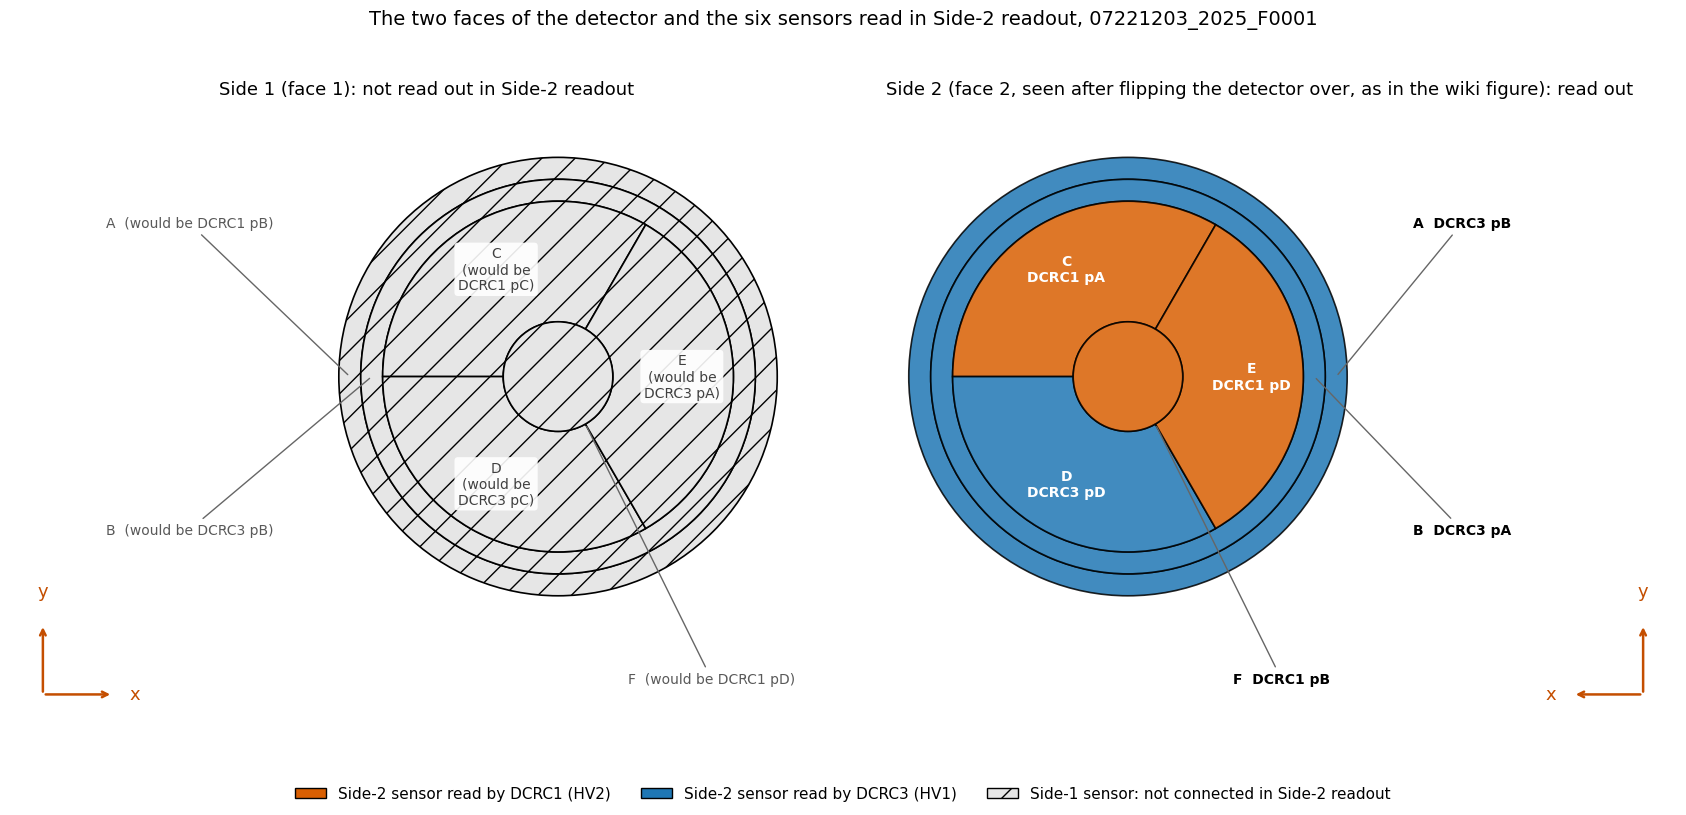

In [2]:
# Geometry of a face as the wiki draws it: A = outer ring, B = second ring, C / D / E = three 120-degree sectors of the
# middle region (E on the right, C upper left, D lower left), F = centre disc. Face 2 is drawn the same way, as seen after
# flipping the detector over; only its x axis points the other way (left).
regions = {   # letter -> (inner radius, outer radius, start angle, end angle) in degrees
    "A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360),
    "C": (0.25, 0.80, 60, 180), "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60),
    "F": (0.00, 0.25, 0, 360),
}
board_colour = {"DCRC1": "#d95f02", "DCRC3": "#1f77b4"}
off_colour = "0.9"
axes_colour = "#c44e00"


def draw_face(ax, chans, side, active):
    """One face; `chans` maps letter -> Channel; the regions are coloured by board if `active`, else greyed out."""
    out = -1 if side == 1 else 1                  # the A and B labels go to the left of face 1, the right of face 2
    for letter, (r_in, r_out, a0, a1) in regions.items():
        c = chans[letter]
        ax.add_patch(Wedge((0, 0), r_out, a0, a1, width=r_out - r_in,
                           facecolor=board_colour[c.dcrc] if active else off_colour, edgecolor="k", linewidth=1.2,
                           alpha=0.85 if active else 1.0, hatch=None if active else "/"))
        board = f"{c.dcrc} {c.board_input}"
        if active:
            text = f"{letter}\n{board}"
        else:
            text = f"{letter}\n(would be\n{board})"
        if letter in "CDE":
            mid = np.deg2rad((a0 + a1) / 2)
            r_mid = (r_in + r_out) / 2 + 0.04
            ax.text(r_mid * np.cos(mid), r_mid * np.sin(mid), text, ha="center", va="center", fontsize=10,
                    fontweight="bold" if active else "normal", color="white" if active else "0.25",
                    bbox=None if active else dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9))
        else:   # the small regions (A, B rings and the F disc) are labelled outside, with a line to the region
            text = f"{letter}  {board}" if active else f"{letter}  (would be {board})"
            xy, xytext, ha = {"A": ((0.95 * out, 0.0), (1.3 * out, 0.7), "right" if out == -1 else "left"),
                              "B": ((0.85 * out, 0.0), (1.3 * out, -0.7), "right" if out == -1 else "left"),
                              "F": ((0.125, -0.217), (0.7, -1.38), "center")}[letter]   # F: line along the D/E boundary
            ax.annotate(text, xy=xy, xytext=xytext, fontsize=10, ha=ha, va="center",
                        color="k" if active else "0.35", fontweight="bold" if active else "normal",
                        arrowprops=dict(arrowstyle="-", color="0.4"))
    # the axes of the wiki figure: +x to the right on face 1, to the left on face 2, +y up on both
    sgn = 1 if side == 1 else -1
    gx = -2.35 if side == 1 else 2.35
    ax.annotate("", xy=(gx + 0.32 * sgn, -1.45), xytext=(gx, -1.45), arrowprops=dict(arrowstyle="->", color=axes_colour, linewidth=1.8))
    ax.annotate("", xy=(gx, -1.13), xytext=(gx, -1.45), arrowprops=dict(arrowstyle="->", color=axes_colour, linewidth=1.8))
    ax.text(gx + 0.42 * sgn, -1.45, "x", color=axes_colour, va="center", ha="center", fontsize=13)
    ax.text(gx, -1.0, "y", color=axes_colour, ha="center", fontsize=13)
    ax.set_xlim(-2.5, 1.3) if side == 1 else ax.set_xlim(-1.3, 2.5)
    ax.set_ylim(-1.6, 1.25)
    ax.set_aspect("equal"); ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(17, 8.2), gridspec_kw=dict(wspace=0.0))
draw_face(axes[0], side1, 1, active=False)
draw_face(axes[1], side2, 2, active=True)
axes[0].set_title("Side 1 (face 1): not read out in Side-2 readout", fontsize=13)
axes[1].set_title("Side 2 (face 2, seen after flipping the detector over, as in the wiki figure): read out", fontsize=13)
handles = [Patch(facecolor=board_colour["DCRC1"], edgecolor="k", label="Side-2 sensor read by DCRC1 (HV2)"),
           Patch(facecolor=board_colour["DCRC3"], edgecolor="k", label="Side-2 sensor read by DCRC3 (HV1)"),
           Patch(facecolor=off_colour, edgecolor="k", hatch="/", label="Side-1 sensor: not connected in Side-2 readout")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=11, frameon=False)
fig.suptitle(f"The two faces of the detector and the six sensors read in Side-2 readout, {DUMP}", fontsize=14)
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.07)
plt.savefig(FIGDIR / f"detector-faces-{DUMP}.png", dpi=110)
plt.show()

**Reading the figure.** Each face has the same six regions. In Side-2 readout the DCRC1 (HV2) inputs pA, pB and pD carry `Side2pC`, `Side2pF` and `Side2pE`, and the DCRC3 (HV1) inputs pA, pB and pD carry `Side2pB`, `Side2pA` and `Side2pD`; the pC inputs and the rest of DCRC4 are not connected, and DCRC4 pA is the trigger input of the NaI array (not on the detector). The Side-1 regions are drawn only to show what the whole detector looks like; the board inputs written in grey are those of the Side-1 readout of the same Setup table, which this series does not use.